# Multi-adapter transfer pruning: совместно vs раздельно
Два независимых LoRA адаптера на одной замороженной Llama: 20% и 80% **удалённых** каналов. «Совместно» означает два последовательных forward/backward на одном батче и один optimizer step; адаптеры не суммируются.

Контроль: два свежих экземпляра той же модели, каждый с одним адаптером. Одинаковы начальные A/B, вложенные маски, порядок батчей, loss, число optimizer steps, LR и eval-набор. Dropout и общий clipping отключены. AdamW имеет независимое состояние каждого параметра — один общий step эквивалентен отдельным steps при отсутствии связующих операций.

Меньший pruning ожидаемо сохраняет лучшее качество, но это **гипотеза**, не assertion. Сравниваем начальные/конечные eval loss, perplexity, token accuracy и динамику. Train loss сам по себе не доказывает обобщение.

Блокнот запускает три изолированных subprocess. Не создаёт checkpoint всей модели: сохраняет только CPU-адаптеры, PruningLens traces, маски и JSON-метрики. Нужен локальный HF cache. Начните с STEPS=2 для smoke, затем 100–500+ для исследования.


In [2]:
from pathlib import Path
import os
import sys
import json
import subprocess
from datetime import datetime

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "lora_transfer_pruning").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
NOTEBOOK = ROOT / "experiments/compare_tp_and_our/prune_and_learn_llama_multiadapter.ipynb"
PYTHON = ROOT / ".venv/bin/python"
EXISTING_RUN = None  # Set a saved run directory to view results without retraining.
RUN_DIR = ROOT / "experiments/compare_tp_and_our/results" / (
    "multiadapter_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)

CONFIG = {
    "model": "meta-llama/Llama-3.1-8B-Instruct",
    "cache_dir": "/glazkov-dev/.cache",
    "gpu": "2",                     # physical GPU; worker sees cuda:0
    "seed": 42,
    "layers": [28, 29, 30],
    "ratios": {"prune20": 0.2, "prune80": 0.8},
    "steps": 60,
    "batch_size": 2,
    "context_length": 128,
    "train_blocks": 128,
    "eval_blocks": 16,
    "eval_every": 10,
    "lr": 2e-4,
    "rank": 16,
    "alpha": 32,
    "atol": 1e-4,
    "rtol": 1e-3,
}
if EXISTING_RUN is not None:
    RUN_DIR = Path(EXISTING_RUN)
    CONFIG = json.loads((RUN_DIR / "config.json").read_text())
else:
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    (RUN_DIR / "config.json").write_text(json.dumps(CONFIG, indent=2))
print(RUN_DIR)


/glazkov-dev/LoRa-Transfer-Pruning/experiments/compare_tp_and_our/results/multiadapter_20261007_140249


## Worker: данные, адаптеры, pruning, обучение и capture
Код следующей ячейки исполняется в дочернем процессе, а не загружает модель в kernel.

Pruning plans строятся на **базовой модели до установки PEFT**. Затем PEFT оборачивает те же Linear внутри bridge; группы сохраняют ссылки на base_layer, поэтому mapper ставит маску на внешний LinearBridge — на сумму W + BA. Это также избегает зависимости DG от активного адаптера. Structural setup здесь не вызывается: это только SP.

Удаляем одинаковые каналы на каждом head; пары RoPE замкнуты заранее. Для 128-dimensional head фактические доли после округления: 20.3125% / 79.6875%. MLP up/gate/down включаются через dependency group. Сохраняем фактические маски и проверяем зануление после переключения адаптера.


In [3]:
def run_worker(config_path, run_dir, mode):
    import copy
    import gc
    import math
    import time
    import importlib.metadata
    import torch
    import torch.nn.functional as F
    from torch.utils.data import DataLoader
    from datasets import Dataset, load_dataset
    from transformers import AutoModelForCausalLM, AutoTokenizer, default_data_collator, set_seed
    from peft import LoraConfig, TaskType, get_peft_model
    from trl import SFTConfig
    from transformer_lens.model_bridge.bridge import TransformerBridge
    from transformer_lens.model_bridge.generalized_components.linear import LinearBridge
    from lora_transfer_pruning.core.multi_adapter_pruning_trainer import MultiAdapterPruningTrainer
    from lora_transfer_pruning.core.prune_task_type import GroupPruneTask, ModelPruneTask
    from lora_transfer_pruning.usecase.local_pruning import LocalPruning
    from pruning_lens.adapter.transfer_pruning.transfer_pruning_tracer import TransferPruningTracer

    cfg = json.loads(Path(config_path).read_text())
    run_dir = Path(run_dir)
    out_dir = run_dir / mode
    out_dir.mkdir(exist_ok=False)
    names = list(cfg["ratios"]) if mode == "joint" else [mode]
    set_seed(cfg["seed"])
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(True)
    device = torch.device("cuda:0")
    started = time.monotonic()
    print("START", mode, flush=True)

    data_path = run_dir / "data.pt"
    if not data_path.exists():
        tokenizer = AutoTokenizer.from_pretrained(cfg["model"], cache_dir=cfg["cache_dir"], local_files_only=True)
        def pack(split, count):
            snapshots = Path(cfg["cache_dir"]) / "datasets--Salesforce--wikitext"
            revision = (snapshots / "refs/main").read_text().strip()
            parquet = snapshots / "snapshots" / revision / "wikitext-2-raw-v1"
            files = sorted(parquet.glob(f"{split}-*.parquet"))
            assert files, f"Missing cached WikiText {split} parquet in {parquet}"
            raw = load_dataset("parquet", data_files=[str(p) for p in files], split="train")
            ids = []
            for text in raw["text"]:
                if text.strip():
                    ids.extend(tokenizer(text, add_special_tokens=False)["input_ids"])
                    ids.append(tokenizer.eos_token_id)
                if len(ids) >= count * cfg["context_length"]:
                    break
            assert len(ids) >= count * cfg["context_length"]
            return torch.tensor(ids[:count * cfg["context_length"]], dtype=torch.long).reshape(count, -1)
        # Official train/validation splits, EOS between documents, no padding.
        torch.save({"train": pack("train", cfg["train_blocks"]),
                    "eval": pack("validation", cfg["eval_blocks"])}, data_path)
    data = torch.load(data_path, weights_only=True)
    train_dataset = Dataset.from_dict({
        "input_ids": data["train"].tolist(),
        "attention_mask": torch.ones_like(data["train"]).tolist(),
        "labels": data["train"].tolist(),
    })
    tokenizer = AutoTokenizer.from_pretrained(cfg["model"], cache_dir=cfg["cache_dir"], local_files_only=True)
    tokenizer.pad_token = tokenizer.eos_token
    # default_data_collator preserves true EOS labels (no PAD=EOS masking).
    model = AutoModelForCausalLM.from_pretrained(
        cfg["model"], cache_dir=cfg["cache_dir"], local_files_only=True,
        dtype=torch.bfloat16, device_map="cuda:0", attn_implementation="eager",
    )
    model.config.use_cache = False
    hf_config = model.config
    bridge = TransformerBridge.boot_transformers(cfg["model"], hf_model=model, dtype=torch.bfloat16)
    model.requires_grad_(True)
    model.eval()

    # Plans use a short forward, never backward; release DG before training.
    local = LocalPruning(bridge, data["train"][:1, :8].to(device))
    plans, manifests = [], {}
    gen = torch.Generator().manual_seed(cfg["seed"] + 100)
    half = hf_config.head_dim // 2
    head_order = torch.randperm(half, generator=gen)
    mlp_order = torch.randperm(hf_config.intermediate_size, generator=gen)
    for name in names:
        ratio = cfg["ratios"][name]
        first_half = head_order[:round(half * ratio)]
        head_idxs = torch.cat((first_half, first_half + half)).sort().values.tolist()
        mlp_idxs = mlp_order[:round(hf_config.intermediate_size * ratio)].sort().values.tolist()
        task = ModelPruneTask(name=name, data={
            **{f"blocks.{layer}.attn.q": GroupPruneTask(None, head_idxs) for layer in cfg["layers"]},
            **{f"blocks.{layer}.mlp.up_proj": GroupPruneTask(None, mlp_idxs) for layer in cfg["layers"]},
        })
        plans.append(local.get_torch_pruning_groups_and_structural_setups(task))
        manifests[name] = {"head_idxs": head_idxs, "mlp_idxs": mlp_idxs,
                           "actual_head_fraction": len(head_idxs) / hf_config.head_dim,
                           "actual_mlp_fraction": len(mlp_idxs) / hf_config.intermediate_size}

    # Wrap existing HF Linear children already owned by LinearBridge.
    # Match raw base linears, not the LinearBridge wrappers themselves.
    target_paths = [
        path for path, component in model.named_modules()
        if isinstance(component, torch.nn.Linear)
        and path.endswith("._original_component")
        and any(f".layers.{i}." in path for i in cfg["layers"])
        and any(f".{projection}." in path for projection in
                ("q_proj", "k_proj", "v_proj", "o_proj", "up_proj", "gate_proj", "down_proj"))
    ]
    assert len(target_paths) == len(cfg["layers"]) * 7, target_paths
    lora_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM, r=cfg["rank"], lora_alpha=cfg["alpha"],
        lora_dropout=0.0, bias="none", target_modules=target_paths,
    )
    set_seed(cfg["seed"] + 1)
    # Environment workaround: installed GPTQModel cannot import against this Transformers.
    # All targets above are ordinary BF16 nn.Linear; skip only quantized dispatch probes.
    from unittest.mock import patch
    with patch("peft.tuners.lora.awq.is_gptqmodel_available", return_value=False), \
         patch("peft.tuners.lora.gptq.is_gptqmodel_available", return_value=False):
        peft_model = get_peft_model(model, lora_config, adapter_name=names[0])
        for name in names[1:]:
            peft_model.add_adapter(name, copy.deepcopy(lora_config))

    def adapter_parameters(name):
        return {path.replace(f".{name}.", ".ADAPTER."): parameter
                for path, parameter in peft_model.named_parameters()
                if (".lora_A." in path or ".lora_B." in path) and f".{name}." in path}
    # Initialize every adapter from the SAME saved tensors, including separate runs.
    init_path = run_dir / "initial_adapter.pt"
    if not init_path.exists():
        torch.save({k: p.detach().cpu().clone() for k, p in adapter_parameters(names[0]).items()}, init_path)
    initial = torch.load(init_path, weights_only=True)
    with torch.no_grad():
        for name in names:
            params = adapter_parameters(name)
            assert params.keys() == initial.keys()
            for key, parameter in params.items():
                parameter.copy_(initial[key])
    local.peft_model = peft_model
    local.active_adapters_source = lambda: peft_model.active_adapters
    local.prepare_model_to_transfer_pruning(plans, rescale=False)
    model.requires_grad_(False)
    for name in names:
        for parameter in adapter_parameters(name).values():
            parameter.requires_grad_(True)

    # Select canonical outer linear boundaries, not aliases or LoRA internals.
    hook_names = sorted({
        point.name
        for layer in cfg["layers"]
        for component in bridge.blocks[layer].modules()
        if isinstance(component, LinearBridge)
        for point in (component.hook_in, component.hook_out)
        if point.name is not None
    })
    probe = data["eval"][:1, :32].to(device)
    assert len(hook_names) == 14 * len(cfg["layers"]), hook_names
    def capture(name):
        peft_model.set_adapter(name)
        peft_model.eval()
        return TransferPruningTracer.capture_hookpoints_activations_with_defects(
            bridge, probe, names_filter=hook_names, compute_gradient=False,
            groups=None,   # SP retains channel shapes; only TL conversion metadata needed.
        ).to_cpu()

    # Non-vacuous preflight: masks really applied to both base+adapter output.
    for name in names:
        trace = capture(name)
        for layer in cfg["layers"]:
            for component, idxs in (
                (bridge.blocks[layer].attn.q, manifests[name]["head_idxs"]),
                (bridge.blocks[layer].mlp.up_proj, manifests[name]["mlp_idxs"]),
            ):
                key = component.hook_out.name
                x = trace.corruptions[key].restore_activation(trace.activations[key])
                if component is bridge.blocks[layer].attn.q:
                    x = x.reshape(*x.shape[:-1], hf_config.num_attention_heads, hf_config.head_dim)
                assert x[..., idxs].count_nonzero().item() == 0, (name, key, "mask inactive")
                assert x.count_nonzero().item() > 0, (name, key, "everything zero")
        torch.save(trace, out_dir / f"{name}_before_trace.pt")
    (out_dir / "masks.json").write_text(json.dumps(manifests, indent=2))

    # Discard graph/plans to avoid retaining autograd graph + original forward tensors.
    del local, plans, trace
    gc.collect()
    torch.cuda.empty_cache()

    param_groups = [{"params": list(adapter_parameters(name).values()), "adapter": name} for name in names]
    base_parameters = [p for path, p in peft_model.named_parameters()
                       if ".lora_A." not in path and ".lora_B." not in path]
    assert all(not p.requires_grad for p in base_parameters)
    # Small exact sentinels plus full optimizer-membership audit.
    base_sentinels = [(p, p.detach().reshape(-1)[:16].cpu().clone()) for p in base_parameters]
    expected_ids = {id(p) for group in param_groups for p in group["params"]}
    assert not expected_ids.intersection(id(p) for p in base_parameters)

    class AuditedAdamW(torch.optim.AdamW):
        def __init__(self, groups):
            super().__init__(groups, lr=cfg["lr"], weight_decay=0.0, foreach=False, fused=False)
            self.audit = []
        def step(self, closure=None):
            assert all(p.grad is None for p in base_parameters), "Base weights received gradients"
            row = {}
            for group in self.param_groups:
                grads = [p.grad for p in group["params"]]
                assert all(g is not None for g in grads), (group["adapter"], "missing gradients")
                norm = torch.stack([g.detach().float().square().sum() for g in grads]).sum().sqrt()
                assert torch.isfinite(norm) and norm > 0, (group["adapter"], norm)
                row[group["adapter"]] = norm.item()
            self.audit.append(row)
            return super().step(closure)

    optimizer = AuditedAdamW(param_groups)

    class ExperimentTrainer(MultiAdapterPruningTrainer):
        def get_train_dataloader(self):
            # Identical batches/order for each adapter and for each control run.
            return self.accelerator.prepare(DataLoader(
                self.train_dataset, batch_size=cfg["batch_size"], shuffle=False,
                collate_fn=default_data_collator, num_workers=0, drop_last=True,
            ))
        def evaluate(self, eval_dataset=None, ignore_keys=None, metric_key_prefix="eval"):
            was_training = self.model.training
            previous = self.model.active_adapters[0]
            metrics = {}
            with torch.no_grad():
                for name in self.task_names:
                    self.model.set_adapter(name)
                    self.model.eval()
                    loss_sum, correct, count = 0.0, 0, 0
                    for block in data["eval"].split(cfg["batch_size"]):
                        ids = block.to(device)
                        logits = self.model(input_ids=ids, use_cache=False).logits[:, :-1].float()
                        target = ids[:, 1:]
                        loss_sum += F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                                    target.reshape(-1), reduction="sum").item()
                        correct += (logits.argmax(-1) == target).sum().item()
                        count += target.numel()
                    loss = loss_sum / count
                    metrics.update({
                        f"{metric_key_prefix}_{name}_loss": loss,
                        f"{metric_key_prefix}_{name}_perplexity": math.exp(loss),
                        f"{metric_key_prefix}_{name}_accuracy": correct / count,
                    })
            self.model.set_adapter(previous)
            self.model.train(was_training)
            self.log(metrics)
            self.control = self.callback_handler.on_evaluate(self.args, self.state, self.control, metrics)
            return metrics

    args = SFTConfig(
        output_dir=str(out_dir / "trainer"), max_steps=cfg["steps"],
        per_device_train_batch_size=cfg["batch_size"], gradient_accumulation_steps=1,
        learning_rate=cfg["lr"], lr_scheduler_type="constant", warmup_steps=0,
        max_grad_norm=0.0, bf16=True, fp16=False, gradient_checkpointing=False,
        logging_steps=1, logging_first_step=True, report_to="none",
        eval_strategy="steps", eval_steps=cfg["eval_every"],
        save_strategy="no", seed=cfg["seed"], data_seed=cfg["seed"],
        dataloader_num_workers=0, remove_unused_columns=False,
        dataset_kwargs={"skip_prepare_dataset": True},
    )
    trainer = ExperimentTrainer(
        model=peft_model, task_names=names, args=args,
        train_dataset=train_dataset, processing_class=tokenizer,
        eval_dataset=Dataset.from_dict({"input_ids": data["eval"].tolist()}),
        data_collator=default_data_collator, optimizers=(optimizer, None),
    )
    assert {id(p) for g in trainer.optimizer.param_groups for p in g["params"]} == expected_ids
    before = trainer.evaluate()
    set_seed(cfg["seed"] + 2)  # same training RNG state in every fresh process
    trainer.train()
    after = trainer.evaluate()
    assert len(optimizer.audit) == cfg["steps"]
    for parameter, snapshot in base_sentinels:
        assert torch.equal(parameter.detach().reshape(-1)[:16].cpu(), snapshot)
    changed = {}
    for name in names:
        state = {k: p.detach().cpu().clone() for k, p in adapter_parameters(name).items()}
        changed[name] = sum(not torch.equal(state[k], initial[k]) for k in state)
        assert changed[name] > 0, (name, "adapter did not learn")
        torch.save(state, out_dir / f"{name}_adapter.pt")
        torch.save(capture(name), out_dir / f"{name}_after_trace.pt")
    result = {
        "mode": mode, "config": cfg, "before": before, "after": after,
        "history": [{"step": 0, **before}, *trainer.state.log_history], "gradient_norms": optimizer.audit,
        "changed_adapter_tensors": changed,
        "seconds": time.monotonic() - started,
        "peak_gpu_gib": torch.cuda.max_memory_allocated() / 2**30,
        "versions": {p: importlib.metadata.version(p) for p in ("torch", "transformers", "peft", "trl")},
    }
    (out_dir / "result.json").write_text(json.dumps(result, indent=2))
    print("DONE", mode, before, after, flush=True)


## Запуск
Лог выводится в kernel и сохраняется в worker.log. Ошибка любого worker останавливает эксперимент. Отдельные модели запускаются после завершения совместной, не занимают GPU одновременно. Для повторного запуска создайте новый RUN_DIR ячейкой конфигурации.


In [4]:
WORKER_BOOTSTRAP = """
import json, sys
from pathlib import Path
root, notebook, config, run_dir, mode = sys.argv[1:]
sys.path.insert(0, root)
namespace = {"Path": Path, "json": json}
for cell in json.loads(Path(notebook).read_text())["cells"]:
    if "worker_definition" in cell.get("metadata", {}).get("tags", []):
        exec("".join(cell["source"]), namespace)
namespace["run_worker"](config, run_dir, mode)
"""
env = dict(os.environ)
env.update(
    CUDA_VISIBLE_DEVICES=CONFIG["gpu"],
    HF_HUB_OFFLINE="1",
    HF_DATASETS_OFFLINE="1",
    HF_HUB_CACHE=CONFIG["cache_dir"],
    CUBLAS_WORKSPACE_CONFIG=":4096:8",
    TOKENIZERS_PARALLELISM="false",
)
for mode in ("joint", *CONFIG["ratios"]):
    if (RUN_DIR / mode / "result.json").exists():
        print("Using completed run:", mode)
        continue
    log_path = RUN_DIR / f"{mode}_worker.log"
    command = [str(PYTHON), "-u", "-c", WORKER_BOOTSTRAP, str(ROOT),
               str(NOTEBOOK), str(RUN_DIR / "config.json"), str(RUN_DIR), mode]
    with log_path.open("w") as log:
        process = subprocess.Popen(command, cwd=ROOT, env=env,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        try:
            for line in process.stdout:
                log.write(line)
                log.flush()
                print(line, end="")
            returncode = process.wait()
        finally:
            if process.poll() is None:
                process.terminate()
                process.wait()
    if returncode:
        raise RuntimeError(f"{mode} failed ({returncode}); see {log_path}")


Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).
START joint

Loading weights: 100%|██████████| 291/291 [00:06<00:00, 47.13it/s]
/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.layers.4._original_component.input_layernorm._original_component.weight', 'model.layers.13._original_component.post_attention_layernorm._original_component.weight', 'model.layers.6._original_component.post_attention_layernorm._original_component.weight', 'model.layers.7._original_component.input_layernorm._original_component.weight', 'model.layers.14._original_component.input_layernorm._original_component.weight', 'model.layers.18._original_component.post_attention_layernorm._original_component.weight', 'model.layers.29._original_component.post_attention_layernorm._original_component.weight', 'model.layers.0._original_componen

## Метрики: качество и эквивалентность расписаний
Сравнивайте joint/prune20 с single/prune20 и joint/prune80 с single/prune80. Разницу между 20% и 80% не следует путать с ошибкой реализации. Step — число обновлений **каждого** адаптера; joint выполняет вдвое больше forward/backward на step.


,run,adapter,phase,loss,perplexity,accuracy
0,joint,prune20,before,2.773383,16.012715,0.509350
1,joint,prune20,after,2.187117,8.909488,0.557579
2,joint,prune80,before,3.349015,28.474660,0.391732
3,joint,prune80,after,2.471320,11.838063,0.523622
4,prune20,prune20,before,2.773383,16.012715,0.509350
5,prune20,prune20,after,2.187117,8.909488,0.557579
6,prune80,prune80,before,3.349015,28.474660,0.391732
7,prune80,prune80,after,2.471320,11.838063,0.523622


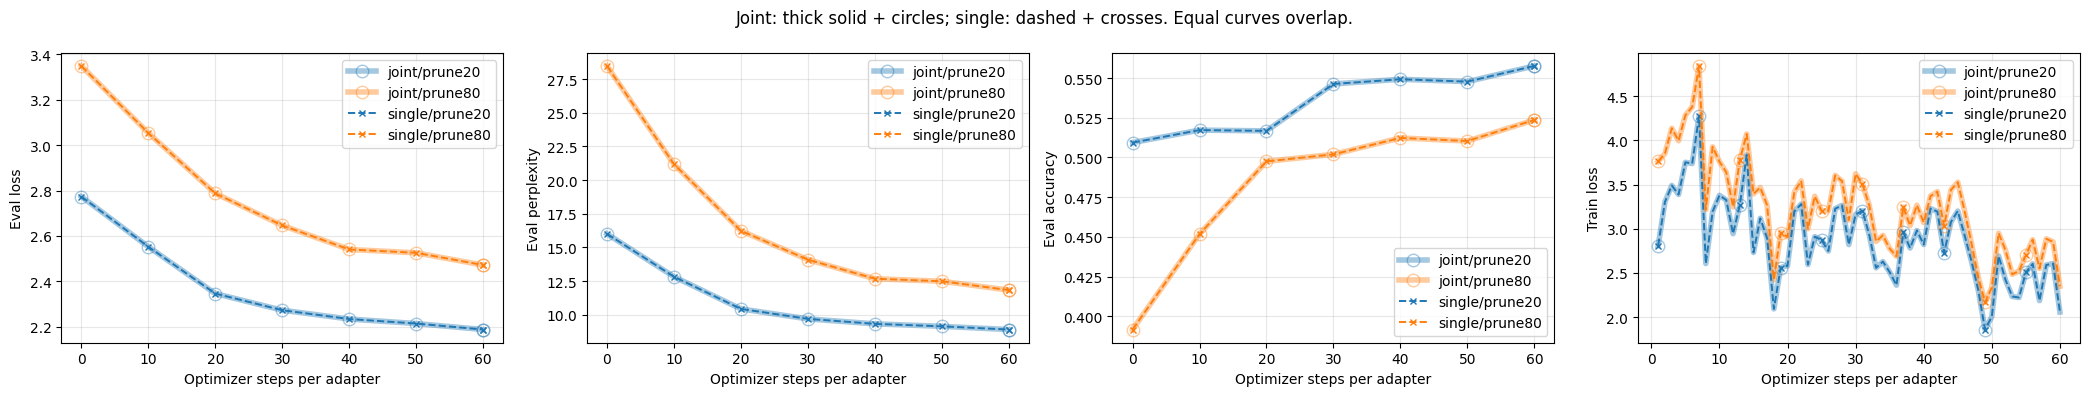

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

results = {mode: json.loads((RUN_DIR / mode / "result.json").read_text())
           for mode in ("joint", *CONFIG["ratios"])}
summary = []
for mode, result in results.items():
    for adapter in (CONFIG["ratios"] if mode == "joint" else [mode]):
        for phase in ("before", "after"):
            summary.append({
                "run": mode, "adapter": adapter, "phase": phase,
                **{metric: result[phase][f"eval_{adapter}_{metric}"]
                   for metric in ("loss", "perplexity", "accuracy")},
            })
summary = pd.DataFrame(summary)
summary.to_csv(RUN_DIR / "metrics_summary.csv", index=False)
display(summary)
fig, axes = plt.subplots(1, 4, figsize=(21, 4))
colors = dict(zip(CONFIG["ratios"], ("tab:blue", "tab:orange")))
styles = {
    "joint": dict(linestyle="-", linewidth=4, alpha=0.4, marker="o",
                  markersize=9, markerfacecolor="none", zorder=2),
    "single": dict(linestyle="--", linewidth=1.4, marker="x",
                   markersize=5, zorder=3),
}
for mode, result in results.items():
    for adapter in (CONFIG["ratios"] if mode == "joint" else [mode]):
        kind = "joint" if mode == "joint" else "single"
        style = dict(color=colors[adapter], label=f"{kind}/{adapter}", **styles[kind])
        for ax, metric in zip(axes[:3], ("loss", "perplexity", "accuracy")):
            key = f"eval_{adapter}_{metric}"
            points = [(row["step"], row[key]) for row in result["history"] if key in row]
            assert points, f"Missing eval series: {mode}/{key}"
            ax.plot(*zip(*points), **style)
            ax.set(xlabel="Optimizer steps per adapter", ylabel=f"Eval {metric}")
        key = f"adapter_loss_{adapter}"
        points = [(row["step"], row[key]) for row in result["history"] if key in row]
        assert points, f"Missing train series: {mode}/{key}"
        axes[3].plot(*zip(*points), markevery=max(1, len(points) // 10), **style)
axes[3].set(xlabel="Optimizer steps per adapter", ylabel="Train loss")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("Joint: thick solid + circles; single: dashed + crosses. Equal curves overlap.")
plt.tight_layout()
fig.savefig(RUN_DIR / "training_dynamics.png", dpi=140, bbox_inches="tight")


## Адаптеры и PruningLens после обучения
Для каждого адаптера — свой forward с соответствующими масками. Один forward не может показать две альтернативные pruning tasks одновременно.

Сохраняются внешние in/out всех Linear выбранных блоков, включая LoRA-сумму, без гигантского кеша всей модели. Сравниваем начальные traces (контроль постановки), конечные traces и A/B веса. Проверки чувствительности: адаптеры обязаны обновиться, градиенты обоих обязаны существовать на каждом step, маски обязаны реально занулять выходы. DIFF не скрывается повышением tolerance. Градиенты здесь намеренно не собираются — это сравнение результатов обучения, не локальных backward.


In [6]:
import torch
from pruning_lens.core.great_comparator import GreatComparator

comparisons = {}
weight_rows = []
for adapter in CONFIG["ratios"]:
    joint_masks = json.loads((RUN_DIR / "joint/masks.json").read_text())[adapter]
    single_masks = json.loads((RUN_DIR / adapter / "masks.json").read_text())[adapter]
    assert joint_masks == single_masks
    for phase in ("before", "after"):
        # weights_only=False only for trusted local PruningTrace dataclasses created above.
        reference_trace = torch.load(RUN_DIR / adapter / f"{adapter}_{phase}_trace.pt",
                               map_location="cpu", weights_only=False)
        candidate_trace = torch.load(RUN_DIR / "joint" / f"{adapter}_{phase}_trace.pt",
                               map_location="cpu", weights_only=False)
        comparison = GreatComparator.compare_traces(
            reference_trace, candidate_trace, atol=CONFIG["atol"], rtol=CONFIG["rtol"],
            compute_gradient=False, store_difference=False,
        )
        assert comparison.activations, "Empty comparison"
        comparisons[adapter, phase] = comparison
        print(adapter, phase)
        comparison.print_summary()
    reference = torch.load(RUN_DIR / adapter / f"{adapter}_adapter.pt", weights_only=True)
    candidate = torch.load(RUN_DIR / "joint" / f"{adapter}_adapter.pt", weights_only=True)
    assert reference.keys() == candidate.keys()
    for name in reference:
        a, b = reference[name].float(), candidate[name].float()
        delta = b - a
        weight_rows.append({
            "adapter": adapter, "parameter": name,
            "exact": torch.equal(a, b), "max_abs": delta.abs().max().item(),
            "rmse": delta.square().mean().sqrt().item(),
            "rel_l2": (delta.norm() / a.norm().clamp_min(1e-12)).item(),
        })
weight_comparison = pd.DataFrame(weight_rows)
display(weight_comparison)
weight_comparison.to_csv(RUN_DIR / "weight_comparison.csv", index=False)

trace_rows = [
    {"adapter": adapter, "phase": phase, "hook": name, "status": str(row.status),
     "max_abs": row.max_abs, "mean_abs": row.mean_abs, "rmse": row.rmse,
     "rel_l2": row.rel_l2, "abs_l2": row.abs_l2}
    for (adapter, phase), comparison in comparisons.items()
    for name, row in comparison.activations.items()
]
trace_comparison = pd.DataFrame(trace_rows)
trace_comparison.to_csv(RUN_DIR / "trace_comparison.csv", index=False)
display(trace_comparison.groupby(["adapter", "phase", "status"]).size())
print("All adapter tensors exactly equal:", bool(weight_comparison["exact"].all()))
print("Results:", RUN_DIR)

history_checks = []
for adapter in CONFIG["ratios"]:
    key = f"adapter_loss_{adapter}"
    joint_loss = [row[key] for row in results["joint"]["history"] if key in row]
    single_loss = [row[key] for row in results[adapter]["history"] if key in row]
    assert len(joint_loss) == len(single_loss) == CONFIG["steps"]
    joint_norms = [row[adapter] for row in results["joint"]["gradient_norms"]]
    single_norms = [row[adapter] for row in results[adapter]["gradient_norms"]]
    history_checks.append({"adapter": adapter, "loss_history_exact": joint_loss == single_loss,
                           "gradient_norms_exact": joint_norms == single_norms})
display(pd.DataFrame(history_checks))

# Negative control: comparator must notice a changed captured activation.
from dataclasses import replace
changed_activations = dict(candidate_trace.activations)
key = next(iter(changed_activations))
changed_activations[key] = changed_activations[key].clone() + 1
negative_control = GreatComparator.compare_traces(
    candidate_trace, replace(candidate_trace, activations=changed_activations),
    atol=CONFIG["atol"], rtol=CONFIG["rtol"], compute_gradient=False, store_difference=False,
)
assert str(negative_control.activations[key].status) == "DIFF"
print("Negative control: detected deliberately changed activation")


prune20 before
[00] blocks.28.attn.q.hook_in
     FWD    OK            shape=(1, 32, 4096) compared=131072 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
[01] blocks.28.attn.q.hook_out
     FWD    OK            shape=(1, 32, 4096) compared=131072 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
[02] blocks.28.attn.k.hook_in
     FWD    OK            shape=(1, 32, 4096) compared=131072 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
[03] blocks.28.attn.k.hook_out
     FWD    OK            shape=(1, 32, 1024) compared=32768 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
[04] blocks.28.attn.v.hook_in
     FWD    OK            shape=(1, 32, 4096) compared=131072 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
[05] blocks.28.attn.v.hook_out
     FWD    OK            shape=(1, 32, 1024) compared=32768 ma

,adapter,parameter,exact,max_abs,rmse,rel_l2
0,prune20,base_model.model.model.layers.28._original_com...,True,0.0,0.0,0.0
1,prune20,base_model.model.model.layers.28._original_com...,True,0.0,0.0,0.0
2,prune20,base_model.model.model.layers.28._original_com...,True,0.0,0.0,0.0
3,prune20,base_model.model.model.layers.28._original_com...,True,0.0,0.0,0.0
4,prune20,base_model.model.model.layers.28._original_com...,True,0.0,0.0,0.0
...,...,...,...,...,...,...
79,prune80,base_model.model.model.layers.30._original_com...,True,0.0,0.0,0.0
80,prune80,base_model.model.model.layers.30._original_com...,True,0.0,0.0,0.0
81,prune80,base_model.model.model.layers.30._original_com...,True,0.0,0.0,0.0
82,prune80,base_model.model.model.layers.30._original_com...,True,0.0,0.0,0.0


adapter  phase   status
prune20  after   OK        42
         before  OK        42
prune80  after   OK        42
         before  OK        42
dtype: int64

All adapter tensors exactly equal: True
Results: /glazkov-dev/LoRa-Transfer-Pruning/experiments/compare_tp_and_our/results/multiadapter_20261007_140249


,adapter,loss_history_exact,gradient_norms_exact
0,prune20,True,True
1,prune80,True,True


Negative control: detected deliberately changed activation


## Выполненный эксперимент — 2026-10-07, cuda:2

60 обновлений каждого адаптера, AdamW lr=2e-4, batch=2, context=128, слои 28–30. Train: первые 128 упакованных блоков WikiText train; eval: первые 16 блоков validation. 20%/80% относятся к каналам выбранных компонентов, не ко всей модели.

| Адаптер | Eval loss до → после | Perplexity до → после | Token accuracy до → после |
|---|---|---|---|
| prune20 | 2.773383 → 2.187117 | 16.0127 → 8.9095 | 50.94% → 55.76% |
| prune80 | 3.349015 → 2.471320 | 28.4747 → 11.8381 | 39.17% → 52.36% |

Joint и single: все 84 тензора A/B побитово равны; 42 hook boundaries для каждого адаптера совпали точно до и после обучения; все 60 train losses и норм градиентов совпали. В каждом адаптере изменились все 42 тензора относительно инициализации. Пик allocated GPU-памяти joint: 15.78 GiB. Это подтверждает независимость адаптеров в данной постановке, но не гарантирует её при общем clipping, dropout или другом optimizer.

Меньший pruning дал лучшее итоговое качество, однако 80% восстановил больше loss относительно своей худшей исходной точки. По одному короткому запуску нельзя утверждать универсальную скорость сходимости; нужен более длинный запуск и несколько seed.

![Training dynamics](results/multiadapter_20261007_135545/training_dynamics.png)

Артефакты: `results/multiadapter_20261007_135545/`. В конфигурации задайте `EXISTING_RUN = ROOT / 'experiments/compare_tp_and_our/results/multiadapter_20261007_135545'`, чтобы пересобрать таблицы и графики без обучения. CSV: `metrics_summary.csv`, `weight_comparison.csv`, `trace_comparison.csv`. Traces и адаптеры — отдельно внутри `joint/`, `prune20/`, `prune80/`. Веса базовой модели не сохранялись.

Тренер библиотеки не менялся: наследник в этом notebook добавляет per-adapter evaluation и фиксированный dataloader. Используется существующий MultiAdapterPruningTrainer для training_step. Локально обойдена несовместимость необязательного GPTQModel при создании BF16 LoRA; зависимости окружения не обновлялись.
